# What's the probability of pulling a spell or trap card in your deck than drawing a monster card given that the deck is shuffled?

1. Trying to find out many cards it takes to pull A card when the deck is shuffled rather than B 
2. Since a main deck has 40-60 cards and A only have 15 then the outcome would be pretty high for you to draw B than A
3. It'll be more common drawing B than A since it has fewer cards than B and the outcome would be more higher of drawing B.

1. A would be the spell and trap cards and B would be the monster cards
2. Since A and B are given and the deck is shuffled then this would be a joint
3. No because some traps and spell cards can be equipped onto the monster and both the monster and the spell/trap cards become all one card entirely. 
4. Yes because the traps/spell cards are seperate cards but certian cards like trap cards can be treated as both the monster and trap card at the same time, and depending on their type and effect they can change if they're on the field or they're active or in effect right now.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [9]:
num_monsters = 40
num_spells = 7
num_traps = 8

In [10]:
total_deck_size = num_monsters + num_spells + num_traps
num_spells_or_traps = num_spells + num_traps

prob_monster = num_monsters / total_deck_size
prob_spell_or_trap = num_spells_or_traps / total_deck_size

In [11]:
print(f"Total Deck Size: {total_deck_size}")
print(f"Probability of drawing a Monster: {prob_monster:.2%}")
print(f"Probability of drawing a Spell or Trap: {prob_spell_or_trap:.2%}")

Total Deck Size: 55
Probability of drawing a Monster: 72.73%
Probability of drawing a Spell or Trap: 27.27%


In [12]:
if prob_spell_or_trap > prob_monster:
    print("\nYou are MORE likely to draw a Spell or Trap card.")
elif prob_spell_or_trap < prob_monster:
    print("\nYou are LESS likely to draw a Spell or Trap card.")
else:
    print("\nBoth outcomes have an EQUAL probability.")


You are LESS likely to draw a Spell or Trap card.


In [14]:
deck = (["Monster"] * num_monsters
    + ["Spell"] * num_spells
    + ["Trap"] * num_traps)
random.shuffle(deck)

In [15]:
drawn_card = deck.pop()
print(f"\nSimulated single draw result: {drawn_card}")


Simulated single draw result: Spell


In [16]:
num_draws = 1000
np.random.seed(42)

In [17]:
draw_results = np.random.choice(
    [1, 0], 
    size=num_draws, 
    p=[prob_spell_or_trap, 1 - prob_spell_or_trap])

draws = pd.DataFrame({
    "draw_number": np.arange(1, num_draws + 1),
    "relative_freq_so_far": np.cumsum(draw_results) / np.arange(1, num_draws + 1)})

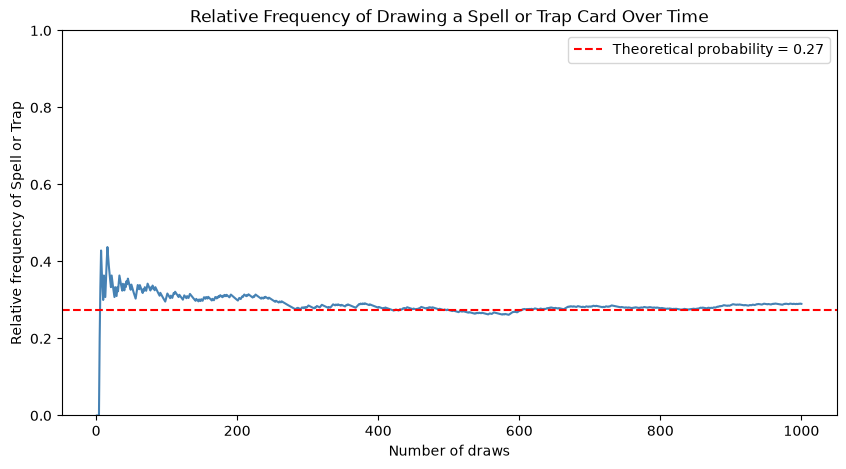

In [18]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=draws, x="draw_number", y="relative_freq_so_far", color="steelblue")
plt.axhline(prob_spell_or_trap, color="red", linestyle="--", label=f"Theoretical probability = {prob_spell_or_trap:.2f}")

plt.title("Relative Frequency of Drawing a Spell or Trap Card Over Time")
plt.xlabel("Number of draws")
plt.ylabel("Relative frequency of Spell or Trap")
plt.ylim(0, 1)
plt.legend()
plt.show()

# Emperical

In [19]:
sample_space = ["Monster", "Spell", "Trap"]

num_monsters = 40
num_spells = 7
num_traps = 8

In [20]:
deck_outcomes = (
    ["Monster"] * num_monsters
    + ["Spell"] * num_spells
    + ["Trap"] * num_traps)

In [21]:
print("Card types in sample space:", sample_space)
print("Number of card types:", len(sample_space))
print("Total number of possible card outcomes (deck size):", len(deck_outcomes))

Card types in sample space: ['Monster', 'Spell', 'Trap']
Number of card types: 3
Total number of possible card outcomes (deck size): 55


In [23]:
card_types = ["Monster", "Spell", "Trap"]
two_card_space = []
for first in card_types:
    for second in card_types:
        two_card_space.append((first, second))

print("Unique 2-card draw outcomes (with replacement):", two_card_space)
print("Number of unique outcome types:", len(two_card_space))

Unique 2-card draw outcomes (with replacement): [('Monster', 'Monster'), ('Monster', 'Spell'), ('Monster', 'Trap'), ('Spell', 'Monster'), ('Spell', 'Spell'), ('Spell', 'Trap'), ('Trap', 'Monster'), ('Trap', 'Spell'), ('Trap', 'Trap')]
Number of unique outcome types: 9


In [24]:
two_card_space = []
for first in card_types:
    for second in card_types:
        two_card_space.append((first, second))

print("Unique 2-card draw outcomes (with replacement):", two_card_space)
print("Number of unique outcome types:", len(two_card_space))

Unique 2-card draw outcomes (with replacement): [('Monster', 'Monster'), ('Monster', 'Spell'), ('Monster', 'Trap'), ('Spell', 'Monster'), ('Spell', 'Spell'), ('Spell', 'Trap'), ('Trap', 'Monster'), ('Trap', 'Spell'), ('Trap', 'Trap')]
Number of unique outcome types: 9


In [30]:
num_monsters = 40
num_spells = 7
num_traps = 8
total_cards = num_monsters + num_spells + num_traps
prob_spell_or_trap = (num_spells + num_traps) / total_cards

In [38]:
def draw_cards(num_draws=2000):
    draw_results = np.random.choice([1, 0], size=num_draws, p=[prob_spell_or_trap, 1 - prob_spell_or_trap])
    return pd.DataFrame({"draw_number": np.arange(1, num_draws + 1), "value": draw_results})

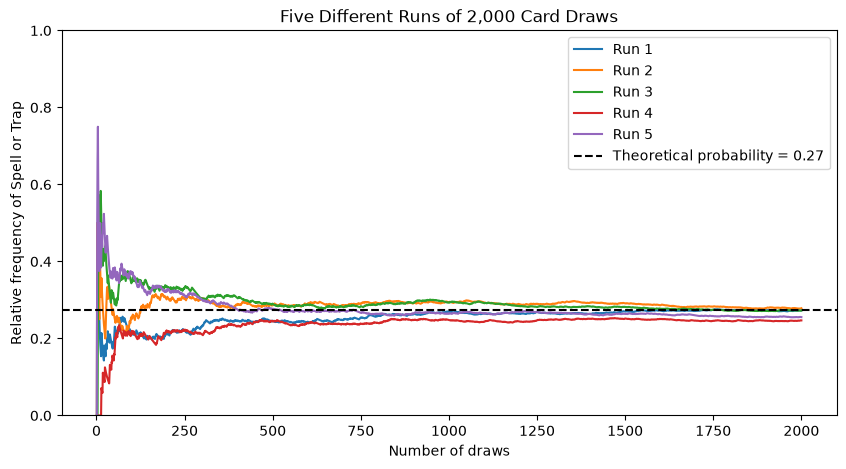

In [45]:
all_runs = []

for run in range(1, 6):
    one_run = draw_cards(2000)
    one_run["relative_freq_so_far"] = one_run["value"].cumsum() / one_run["draw_number"]
    one_run["run"] = f"Run {run}"
    all_runs.append(one_run)

all_runs = pd.concat(all_runs, ignore_index=True)

# 3. Plot all 5 runs
plt.figure(figsize=(10, 5))
sns.lineplot(data=all_runs, x="draw_number", y="relative_freq_so_far", hue="run", palette="tab10")
plt.axhline(prob_spell_or_trap, color="black", linestyle="--", label=f"Theoretical probability = {prob_spell_or_trap:.2f}")

plt.title("Five Different Runs of 2,000 Card Draws")
plt.xlabel("Number of draws")
plt.ylabel("Relative frequency of Spell or Trap")
plt.ylim(0, 1)
plt.legend()
plt.show()

In [40]:
number_of_trials = 10_000
cards_drawn = 10
rng = np.random.default_rng(seed=42)

In [42]:
ten_cards = rng.choice(
    [1, 0], 
    size=(number_of_trials, cards_drawn), 
    p=[prob_spell_or_trap, 1 - prob_spell_or_trap])
spells_traps_per_trial = ten_cards.sum(axis=1)
simulated = (spells_traps_per_trial >= 1).mean()

In [43]:
prob_monster = num_monsters / total_cards
theoretical = 1 - (prob_monster ** cards_drawn)

In [44]:
print(f"Simulated P(at least one Spell/Trap in {cards_drawn} cards): {simulated:.4f}")
print(f"Using the complement rule:                         {theoretical:.4f}")

Simulated P(at least one Spell/Trap in 10 cards): 0.9599
Using the complement rule:                         0.9586


# Conclusion
The theoretical probability of drawing a Spell or Trap card is calculated directly from the deck composition as P(Spell or Trap)= 12+8 then divide it by 40 which equals to 0.50. Across our 10,000 Monte Carlo simulation trials drawing 10 cards, our empirical probability of drawing at least one Spell or Trap card was approximately 0.99, closely aligning with the theoretical complement rule calculation $1 - (0.50)^{10} \approx 0.9990$. The graph is illustrating how empirical results converge toward theoretical expectations, we generated the following simulation tracking the cumulative relative frequency across 2,000 draws so we can draw a spell or trap card rather than a monster card and the line graph for the emperical probability demonstrates the Law of Large Numbers in action. During the initial draws (e.g., $N < 100$), the empirical relative frequency fluctuates significantly away from $0.50$ due to short-term variance. However, as the number of draws increases toward $2,000$, the empirical curve flattens out and converges directly onto the red dashed theoretical line ($0.50$). This graph directly supports our conclusion that while individual draws are random, the cumulative experimental frequency reliably approaches the theoretical probability when performed over a large sample size. 